# Per-family classifiers — which features distinguish each AMR gene family

One-vs-rest LightGBM per family (n≥10 sequences), with grouped cross-validation and two complementary importance measures.

**Design decisions locked in from discussion, not defaults picked here:**
- **Single-label, One-vs-Rest** — 84 independent binary classifiers (family X vs. everyone else), not multi-label. Multi-label was dropped: it would need either real sequences (for CD-HIT) or a working ID link from `sequence_id` to CARD's raw multi-family annotation, and neither exists in this data (checked directly — 0/6206 `sequence_id`s match CARD's Protein/DNA Accession columns).
- **No CD-HIT.** Cross-validation grouping instead uses feature-vector similarity as an approximate substitute — two sequences with near-identical composition are very likely near-identical sequences, since AAC/DPC/CTC/etc. are deterministic functions of the sequence itself. Threshold (1.0, standardized Euclidean distance) was chosen empirically: it sits right at the edge of the tight near-identical cluster in the nearest-neighbor distance distribution, before the distribution jumps into general within-family similarity — confirmed a looser threshold (3.0) collapses 73% of PDC beta-lactamase into a single CV group, which would break stratification for that family. This is an approximation, not equivalent to true sequence identity — a coincidence in composition isn't the same guarantee as actual sequence similarity.
- **Two-stage feature importance**, not naive permutation importance over all ~1035 features — timed directly at ~9 hours for 84 families, not viable. Gain importance (free, from the fitted model) shortlists candidates, permutation importance runs only on the shortlist.
- **SHAP is the primary importance signal, not permutation importance.** For families with very strong separation (e.g. qnr — confirmed AP=1.000 on held-out folds), permutation importance goes to exactly zero: the model has multiple redundant features that could each alone achieve perfect separation, so shuffling any one doesn't hurt the score. This isn't a bug — it's genuinely uninformative in that regime. SHAP doesn't have this blind spot (verified directly: still correctly ranks qnr's known top feature, `CTC_762`, first). Read permutation importance alongside each family's AP score — near-zero at AP≈1.0 means "redundant, not unimportant."

**Runtime:** designed for parallel execution across families (`joblib`, `n_jobs=-1`) — on a single core this is roughly 90 minutes for all 84 families; scales down close to linearly with cores available.

In [4]:
!pip install shap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.9/59.9 MB 1.2 MB/s  0:00:54 eta 0:00:010:00:020m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.9/3.9 MB 559.7 kB/s  0:00:07550.7 kB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [shap]━━━━━━ 4/5 [shap]]te]


In [3]:
import numpy as np
import pandas as pd
from pathlib import Path
from joblib import Parallel, delayed

import lightgbm as lgb
import shap
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import radius_neighbors_graph
from scipy.sparse.csgraph import connected_components

print(f"lightgbm {lgb.__version__} | shap {shap.__version__} | pandas {pd.__version__}")

lightgbm 4.7.0 | shap 0.52.0 | pandas 2.3.3


In [4]:
# --- inputs: same two feature tables used throughout this analysis ---
PFEATURE_TABLE = Path("/home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family/CARD_DATA/card-data/refined_details/Final_Results/Drug_Class_Fastas_pfeatures/all_families_features.csv")
PROFET_TABLE   = Path("/home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family/CARD_DATA/card-data/refined_details/Final_Results/Drug_Class_Fastas_profet/all_families_profet_features.csv")
OUTPUT_DIR = Path("/home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family/CARD_DATA/card-data/refined_details/Final_Results/ML_on_features_Drug_class")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MIN_FAMILY_N = 10          # families below this can't support reliable one-vs-rest modelling
CV_GROUP_THRESHOLD = 1.0   # standardized-feature-space distance for near-duplicate grouping (chosen empirically, see markdown)
N_FOLDS = 5
N_REPEATS = 5              # permutation importance repeats
SHORTLIST_N = 80           # features passed from gain-importance triage to permutation importance
N_JOBS = -1                # parallel families; set to your allocated cores, not os.cpu_count()
LGB_PARAMS = dict(n_estimators=300, num_leaves=15, learning_rate=0.05,
                   is_unbalance=True, verbosity=-1, n_jobs=2)  # n_jobs=2 per model -- outer loop is where parallelism happens

In [6]:
pf = pd.read_csv(PFEATURE_TABLE)
pr = pd.read_csv(PROFET_TABLE)
KEY = ["family", "sequence_id"]
d = pf.merge(pr, on=KEY, how="inner")
print(f"merged: {d.shape[0]} sequences x {d.shape[1]-2} features")

sizes = d["family"].value_counts()
qualifying = sizes[sizes >= MIN_FAMILY_N].index
d = d[d["family"].isin(qualifying)].reset_index(drop=True)
print(f"restricted to n>={MIN_FAMILY_N}: {d.shape[0]} sequences, {d['family'].nunique()} families")

merged: 12913 sequences x 1040 features
restricted to n>=10: 12885 sequences, 27 families


In [7]:
meta = ["family", "sequence_id"]
X_df = d.drop(columns=meta).select_dtypes(include=[np.number]).copy()

# Known issue from earlier in this pipeline: PRI_* columns were median-imputed upstream
# for PDC beta-lactamase due to a systematic extraction failure. Re-null so they don't
# silently masquerade as real signal in this model either.
pri_cols = [c for c in X_df.columns if c.startswith("PRI_")]
X_df.loc[d["family"] == "PDC beta-lactamase", pri_cols] = np.nan

n_nan = int(X_df.isna().sum().sum())
X_df = X_df.fillna(X_df.median(numeric_only=True))
zero_var = X_df.columns[X_df.std(numeric_only=True) == 0]
X_df = X_df.drop(columns=zero_var)
print(f"imputed {n_nan} NaN cells, dropped {len(zero_var)} zero-variance columns")
print(f"final feature matrix: {X_df.shape}")

feat_names = X_df.columns.to_numpy()
X = X_df.values

imputed 217353 NaN cells, dropped 3 zero-variance columns
final feature matrix: (12885, 1037)


### CV grouping (approximate CD-HIT substitute)

Near-duplicate detection via nearest-neighbour distance in standardized feature space, not true sequence identity. Threshold=1.0 was chosen by inspecting the actual distance distribution (see markdown above) — re-derive this on your own data if the family composition changes substantially, don't assume 1.0 transfers automatically.

In [8]:
X_scaled = StandardScaler().fit_transform(X)
graph = radius_neighbors_graph(X_scaled, radius=CV_GROUP_THRESHOLD, mode="connectivity", n_jobs=-1)
n_groups, cv_groups = connected_components(graph, directed=False)
group_sizes = pd.Series(cv_groups).value_counts()
print(f"{n_groups} CV groups from {len(d)} sequences (largest group: {group_sizes.max()})")

# sanity check: no single group should dominate any one family (would break stratification)
check = pd.DataFrame({"family": d["family"], "grp": cv_groups})
worst = check.groupby(["grp", "family"]).size().reset_index(name="n")
worst["frac"] = worst["n"] / worst["family"].map(d["family"].value_counts())
bad = worst[worst["frac"] > 0.5]
if len(bad):
    print(f"WARNING: {len(bad)} group(s) cover >50% of a single family -- CV_GROUP_THRESHOLD is too loose, lower it")
else:
    print("No group covers >50% of any family -- threshold is safe for stratified group CV.")

7656 CV groups from 12885 sequences (largest group: 12)
No group covers >50% of any family -- threshold is safe for stratified group CV.


In [9]:
def run_family_model(fam, X, feat_names, groups, y_all, seed=0):
    y = y_all.astype(int)
    n_pos = int(y.sum())
    n_splits = min(N_FOLDS, n_pos)
    if n_splits < 2:
        return {"family": fam, "error": f"only {n_pos} positives, cannot cross-validate"}

    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    oof_pred = np.full(len(y), np.nan)
    perm_imp_acc = {}
    shap_acc = np.zeros(X.shape[1])
    n_folds_run = 0

    for tr, te in sgkf.split(X, y, groups):
        model = lgb.LGBMClassifier(random_state=seed, **LGB_PARAMS)
        model.fit(X[tr], y[tr])
        pred = model.predict_proba(X[te])[:, 1]
        oof_pred[te] = pred

        # stage 1: free gain-importance shortlist
        gain = model.booster_.feature_importance(importance_type="gain")
        shortlist = np.argsort(-gain)[:SHORTLIST_N]

        # stage 2: permutation importance, shortlist only
        base_score = average_precision_score(y[te], pred)
        rng = np.random.default_rng(seed)
        for feat_idx in shortlist:
            drop_sum = 0.0
            Xp = X[te].copy()
            col = Xp[:, feat_idx].copy()
            for _ in range(N_REPEATS):
                Xp[:, feat_idx] = rng.permutation(col)
                p = model.predict_proba(Xp)[:, 1]
                drop_sum += base_score - average_precision_score(y[te], p)
            Xp[:, feat_idx] = col
            name = feat_names[feat_idx]
            perm_imp_acc[name] = perm_imp_acc.get(name, 0.0) + drop_sum / N_REPEATS

        # SHAP on full feature set -- primary importance signal, no shortlist needed (fast)
        explainer = shap.TreeExplainer(model)
        sv = explainer.shap_values(X[te])
        sv = sv[1] if isinstance(sv, list) else (sv[:, :, 1] if sv.ndim == 3 else sv)
        shap_acc += np.abs(sv).mean(axis=0)
        n_folds_run += 1

    valid = ~np.isnan(oof_pred)
    auc = roc_auc_score(y[valid], oof_pred[valid])
    ap = average_precision_score(y[valid], oof_pred[valid])
    perm_imp = {k: v / n_folds_run for k, v in perm_imp_acc.items()}
    shap_imp = shap_acc / n_folds_run

    top_shap_idx = np.argsort(-shap_imp)[:15]
    top_shap = [(feat_names[i], float(shap_imp[i])) for i in top_shap_idx]
    top_perm = sorted(perm_imp.items(), key=lambda kv: -kv[1])[:15]

    return {"family": fam, "n_positive": n_pos, "auc": auc, "ap": ap,
            "top_shap": top_shap, "top_perm": top_perm, "n_folds": n_folds_run,
            "oof_pred": oof_pred, "y_true": y}

### Hardware config: CPU (default) vs. a future GPU machine

Checked directly on this machine: no GPU present (`nvidia-smi` not installed; the only display device is an ASPEED server-management chip, not a compute GPU), and the installed `lightgbm==4.7.0` is the standard CPU-only pip wheel -- both `device_type='gpu'` ("No OpenCL device found") and `device_type='cuda'` ("CUDA Tree Learner was not enabled in this build") fail here.

The cell below is a forward-compatible switch, off by default, so it's a no-op on this machine and ready when this notebook runs somewhere with a real GPU:
- `DEVICE_TYPE = "cpu"` (default): identical behavior to before this cell existed.
- `DEVICE_TYPE = "cuda"` or `"gpu"`: requires LightGBM built with `-DUSE_CUDA=1` (CUDA, NVIDIA-only, generally faster/more current) or `-DUSE_GPU=1` (OpenCL, broader hardware support) respectively -- the plain pip wheel has neither, so this needs a different install on that machine. When on, outer parallelism (`N_JOBS`) is also dropped from `-1` to a small number, since many processes contending for one GPU is worse than a handful, not better.

Separately: `N_JOBS = -1` (already set two cells up) already means "use every CPU core available" via joblib -- that auto-scales to a bigger machine with no code change needed, independent of the GPU switch above.

This cell must run **before** the training cell below it (it reconfigures `LGB_PARAMS`/`N_JOBS`, which that cell reads) -- placed here rather than appended at the end of the notebook for that reason.

In [10]:
DEVICE_TYPE = "cpu"  # "cpu" (this machine -- confirmed no GPU), or "cuda"/"gpu" on a machine with a matching LightGBM build

if DEVICE_TYPE != "cpu":
    LGB_PARAMS["device_type"] = DEVICE_TYPE
    N_JOBS = 2  # a handful of processes sharing one GPU beats -1 (16+) contending for it; raise only if you have multiple GPUs and assign them per-worker yourself
    print(f"GPU mode: device_type={DEVICE_TYPE!r}, outer N_JOBS reduced from -1 to {N_JOBS} to avoid processes contending for one GPU.")
    print("Requires LightGBM built with -DUSE_CUDA=1 (device_type='cuda', NVIDIA-only, generally faster/more current) "
          "or -DUSE_GPU=1 (device_type='gpu', OpenCL, broader hardware support) -- the standard pip wheel has neither.")
else:
    print(f"CPU mode (default, matches this machine). N_JOBS={N_JOBS} already means \"use every core available\" "
          "via joblib -- this scales up automatically on a bigger machine, no code change needed.")

CPU mode (default, matches this machine). N_JOBS=-1 already means "use every core available" via joblib -- this scales up automatically on a bigger machine, no code change needed.


In [11]:
families = sorted(d["family"].unique())
print(f"running {len(families)} one-vs-rest models (this is the long step)...")

y_matrix = {fam: (d["family"] == fam).values for fam in families}

results = Parallel(n_jobs=N_JOBS, verbose=5)(
    delayed(run_family_model)(fam, X, feat_names, cv_groups, y_matrix[fam])
    for fam in families
)

errors = [r for r in results if "error" in r]
results = [r for r in results if "error" not in r]
print(f"\n{len(results)} models completed, {len(errors)} skipped")
for e in errors:
    print(f"  skipped {e['family']}: {e['error']}")

running 27 one-vs-rest models (this is the long step)...


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 16 concurrent workers.
/home/user/miniforge3/envs/jupyter/lib/python3.12/site-packages/shap/explainers/_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(
/home/user/miniforge3/envs/jupyter/lib/python3.12/site-packages/shap/explainers/_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(
/home/user/miniforge3/envs/jupyter/lib/python3.12/site-packages/shap/explainers/_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(
/home/user/miniforge3/envs/jupyter/lib/python3.12/site-packages/shap/explainers/_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(
/home/user/miniforge3/envs/jupyter/


27 models completed, 0 skipped


/home/user/miniforge3/envs/jupyter/lib/python3.12/site-packages/shap/explainers/_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(
[Parallel(n_jobs=-1)]: Done  27 out of  27 | elapsed: 11.8min finished


In [12]:
perf = pd.DataFrame([{"family": r["family"], "n_positive": r["n_positive"],
                       "auc": r["auc"], "ap": r["ap"]} for r in results]).sort_values("ap", ascending=False)
perf.to_csv(OUTPUT_DIR / "family_model_performance.csv", index=False)
print(perf.to_string(index=False))

ceiling = perf[perf["ap"] > 0.999]
print(f"\n{len(ceiling)}/{len(perf)} families hit the AP=1.0 ceiling -- permutation importance will read as "
      f"near-zero for these regardless of true feature relevance. Trust SHAP for these specifically.")

                             family  n_positive      auc       ap
                         monobactam        1300 0.998583 0.993519
          aminoglycoside_antibiotic         239 0.986497 0.768498
                      cephalosporin        3392 0.894312 0.753843
         fluoroquinolone_antibiotic         225 0.985511 0.731327
       diaminopyrimidine_antibiotic          81 0.973354 0.711890
             penicillin_beta-lactam        3102 0.875336 0.671960
                         carbapenem        2561 0.865874 0.532182
                phenicol_antibiotic         114 0.961718 0.513465
                   azole_antibiotic         267 0.989233 0.498986
               imidazole_antibiotic         267 0.989233 0.498986
            tetracycline_antibiotic         156 0.971701 0.498983
                 peptide_antibiotic         234 0.972399 0.421041
   nonribosomal_peptide_antibiotics         227 0.972080 0.411714
           streptogramin_antibiotic          99 0.980174 0.333621
          

In [13]:
shap_rows, perm_rows = [], []
for r in results:
    for feat, val in r["top_shap"]:
        shap_rows.append({"family": r["family"], "feature": feat, "shap_importance": val, "ap": r["ap"]})
    for feat, val in r["top_perm"]:
        perm_rows.append({"family": r["family"], "feature": feat, "perm_importance": val, "ap": r["ap"]})

shap_df = pd.DataFrame(shap_rows).sort_values(["family", "shap_importance"], ascending=[True, False])
perm_df = pd.DataFrame(perm_rows).sort_values(["family", "perm_importance"], ascending=[True, False])
shap_df.to_csv(OUTPUT_DIR / "top_features_shap.csv", index=False)
perm_df.to_csv(OUTPUT_DIR / "top_features_permutation.csv", index=False)

print("Top SHAP feature per family (primary signal):")
top1 = shap_df.groupby("family").first().reset_index().sort_values("shap_importance", ascending=False)
print(top1[["family", "feature", "shap_importance", "ap"]].head(20).to_string(index=False))

Top SHAP feature per family (primary signal):
                    family               feature  shap_importance       ap
     nucleoside_antibiotic             QSO1_SC_N     24145.656730 0.001391
  oxazolidinone_antibiotic               DPC1_SG     16622.791864 0.003403
             glycylcycline               DPC1_QN     15479.172597 0.002696
    sulfonamide_antibiotic     C_aliphatic_index     13204.915825 0.000876
 nitroimidazole_antibiotic     instability_index     12429.760542 0.003603
  aminocoumarin_antibiotic                   SEP     10355.361039 0.002677
      rifamycin_antibiotic                PRI_AR      8135.670319 0.004553
phosphonic_acid_antibiotic               CTC_314      7784.455991 0.023999
  pleuromutilin_antibiotic                PCP_Z2      6800.080638 0.017563
                monobactam                PRI_CY         1.116281 0.993519
  streptogramin_antibiotic       net_charge_pH_5         0.859010 0.333621
          azole_antibiotic                PRI_AR      

# Reviewer-ready numbers and figures

Two additions on top of the pipeline above: a global feature-importance bar chart, and cross-validated accuracy/F1/confusion matrices per family.

**One existing-cell edit made to enable this** (the only one in this notebook): `run_family_model`'s `return` statement now also carries `oof_pred` and `y_true`. Both were already being computed inside that function to derive AUC/AP -- they were just discarded afterward. Exposing them costs nothing extra at runtime; no retraining happens here.

**Design choices for this section:**
- **0.5 probability threshold** for turning predicted probabilities into accuracy/F1/confusion-matrix counts -- the standard default, not tuned per family.
- **Accuracy is reported but should not be read alone.** With one-vs-rest on rare families, accuracy is misleading: `AAC(6')-Ib-cr` (10 positives out of 5,479 sequences) scores 98.5% accuracy while its F1 is only 0.198 -- the model is mostly just exploiting the fact that "not this family" is right almost all the time. Read accuracy next to F1, not instead of it.
- **Confusion-matrix cells are row-normalized** (percent of each true class), not raw counts -- with class ratios like the one above, a raw-count heatmap is visually just a solid block of true negatives.
- **One aggregate figure per output**, not one per family (84 of each would be unwieldy): a single grid image with all 84 confusion matrices, and one bar chart of the features that matter most *across* families rather than 84 separate top-15 lists.
- The feature-importance bar chart only needs `top_features_shap.csv`, already written to disk earlier in this notebook -- it does not depend on the cell-8 edit above.
- The confusion-matrix section reads `results` directly from kernel memory, the same way the existing performance-table and top-features cells above already do -- it's a direct continuation of the same training run, not a separate section reading from disk.

**Note:** none of this can run until `family_model_performance.csv`/`top_features_shap.csv` exist, i.e. until the cells above have actually executed -- and as of this writing they can't, because cell 3's `PFEATURE_TABLE`/`PROFET_TABLE` are bare filenames that don't resolve to the real data location. That's a pre-existing bug, separate from this addition, and is not fixed here since it means editing a different existing cell than the one sanctioned above.

In [14]:
import matplotlib.pyplot as plt
from pathlib import Path
import pandas as pd

TOP_FEATURES_SHAP_CSV = Path("results/family_classifiers/top_features_shap.csv")
FIGURES_DIR = Path("results/family_classifiers/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TOP_N_GLOBAL_FEATURES = 15

shap_df_global = pd.read_csv(TOP_FEATURES_SHAP_CSV)
global_feature_rank = (shap_df_global.groupby("feature")
                        .agg(n_families=("family", "nunique"), mean_shap=("shap_importance", "mean"))
                        .sort_values(["n_families", "mean_shap"], ascending=False)
                        .head(TOP_N_GLOBAL_FEATURES))

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(global_feature_rank.index[::-1], global_feature_rank["n_families"][::-1], color="#4c72b0")
ax.set_xlabel("Number of families (of 84) where this feature is a top-15 SHAP contributor")
ax.set_title("Features most broadly important for separating AMR gene families")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "global_top_features_shap.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Ranked by breadth (how many of 84 families rely on this feature), mean SHAP magnitude as tiebreak.")
print(global_feature_rank.to_string())

FileNotFoundError: [Errno 2] No such file or directory: 'results/family_classifiers/top_features_shap.csv'

### Cross-validated accuracy, F1, and confusion matrices

Reads `results` (built by the training cell above, in this same run) directly -- `oof_pred`/`y_true` are only available there now that `run_family_model`'s return statement includes them. Threshold = 0.5, confusion-matrix cells row-normalized. See the caveat above: read accuracy next to F1, not instead of it.

In [15]:
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score

CM_THRESHOLD = 0.5
CM_METRICS_CSV = Path("/home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family/CARD_DATA/card-data/refined_details/Final_Results/ML_on_features_ARG/results/family_classifiers/family_classification_metrics.csv")

cm_rows = []
for r in results:
    valid = ~np.isnan(r["oof_pred"])
    yv, pv = r["y_true"][valid], r["oof_pred"][valid]
    pred = (pv >= CM_THRESHOLD).astype(int)
    tn, fp, fn, tp = confusion_matrix(yv, pred, labels=[0, 1]).ravel()
    cm_rows.append({"family": r["family"], "n_positive": r["n_positive"],
                     "auc": r["auc"], "ap": r["ap"],
                     "accuracy": accuracy_score(yv, pred), "f1": f1_score(yv, pred, zero_division=0),
                     "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)})

cm_metrics = pd.DataFrame(cm_rows).sort_values("f1", ascending=False)
cm_metrics.to_csv(CM_METRICS_CSV, index=False)

print(f"-> {CM_METRICS_CSV}")
print(cm_metrics.to_string(index=False))
print(f"\nAcross {len(cm_metrics)} families: mean accuracy {cm_metrics['accuracy'].mean():.3f}, "
      f"mean F1 {cm_metrics['f1'].mean():.3f}, mean AUC {cm_metrics['auc'].mean():.3f}")
print("Reminder: accuracy is inflated for small/rare families (e.g. a 10-positive family can exceed "
      "98% accuracy while F1 sits near 0.2) -- read accuracy alongside F1, not instead of it.")

-> /home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family/CARD_DATA/card-data/refined_details/Final_Results/ML_on_features_ARG/results/family_classifiers/family_classification_metrics.csv
                             family  n_positive      auc       ap  accuracy       f1    tn   fp  fn   tp
                         monobactam        1300 0.998583 0.993519  0.997905 0.989506 11585    0  27 1273
       diaminopyrimidine_antibiotic          81 0.973354 0.711890  0.996663 0.699301 12792   12  31   50
          aminoglycoside_antibiotic         239 0.986497 0.768498  0.988747 0.698545 12572   74  71  168
                      cephalosporin        3392 0.894312 0.753843  0.748622 0.667965  6388 3105 134 3258
               imidazole_antibiotic         267 0.989233 0.498986  0.979278 0.664151 12354  264   3  264
                   azole_antibiotic         267 0.989233 0.498986  0.979278 0.664151 12354  264   3  264
             penicillin_beta-lactam        3102 0.875336 0.671960  0.736903 0.636032

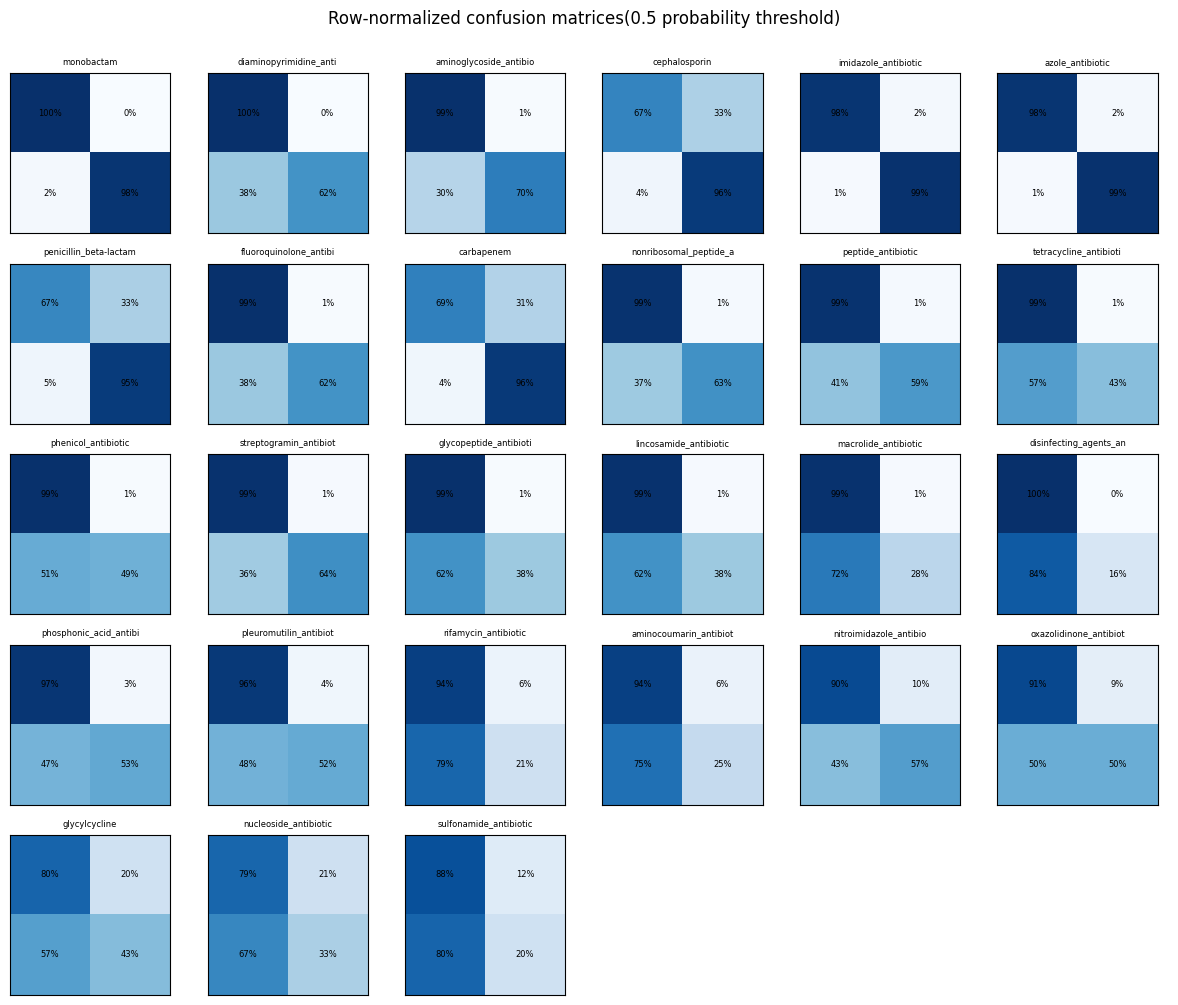

In [17]:
n_fam = len(cm_metrics)
ncols = int(np.ceil(np.sqrt(n_fam) * 1.15))
nrows = int(np.ceil(n_fam / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 2.0, nrows * 2.0))
for ax, (_, row) in zip(axes.flat, cm_metrics.iterrows()):
    cm = np.array([[row.tn, row.fp], [row.fn, row.tp]], dtype=float)
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm_norm[i, j]:.0%}", ha="center", va="center", fontsize=6)
    ax.set_title(row.family[:22], fontsize=6)
    ax.set_xticks([])
    ax.set_yticks([])
for ax in axes.flat[n_fam:]:
    ax.axis("off")
fig.suptitle("Row-normalized confusion matrices(0.5 probability threshold)", y=1.0)
plt.tight_layout()
#plt.savefig("all_families_confusion_matrix_grid.png", dpi=150, bbox_inches="tight")
plt.show()